# Jamnagar Crude Slate Model v4: Venezuelan Merey vs Russian Urals (assay-based LP)

**Question:** Does swapping Russian Urals for heavy, high-sulfur Venezuelan Merey make Reliance more money per barrel at today's prices? How much Merey can Jamnagar absorb before the advantage disappears?

**What's new in v4:** yields are no longer assumed. A **linear program (LP)** splits each crude into distillation cuts using public **crude assays**. It then routes every cut through Jamnagar-style units (vacuum unit, coker, FCC, hydrocracker, reformer, hydrotreaters) to maximise margin within **unit capacities**. Product yields, processing cost, hydrogen use, petcoke and sulfur all come out of the optimisation.

**Pricing date:** 22 Oct 2026 (live pull, 13:50 IST). Each input is tagged **Sourced** (published, with source and date) or **Estimate** (not public), and every estimate has a low and high value.

> Author: Mishu Kumar · Educational research, not investment advice. Sources at the end.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from scipy.optimize import brentq
import refinery_lp as lp

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
MEREY_C, URALS_C = "#B4532A", "#2F5D8A"
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", 80)

## 1. Inputs

### 1a. Market and contract inputs

Edit this table to update the model. It is also saved as `inputs.csv`.

In [2]:
S, E = "Sourced", "Estimate"
INPUTS = pd.DataFrame([
 # key,                 base,   low,    high,  type, unit,      source / basis
 ("brent",              112.3,  100.0,  120.0, S, "$/bbl",   "Oilprice.com live futures, 22 Oct 2026 13:50 IST ($112.31)"),
 ("merey_diff",         -16.5,  -20.4,  -12.0, S, "$/bbl",   "Sep official Merey $93.75 (Oilprice/OPEC) vs EIA Sep Brent $114.16 = −20.4; JV deals −12/−13 (Reuters, 22 Sep); base = midpoint"),
 ("merey_freight",        9.0,    8.0,   10.0, S, "$/bbl",   "Business Standard, 14 Aug 2026: Americas→India freight ~$8–10/bbl"),
 ("merey_insurance",      0.75,   0.4,    1.5, E, "$/bbl",   "War-risk, cargo cover, OFAC screening; no public figure"),
 ("urals_dap_diff",       0.0,   -2.0,    8.0, S, "$/bbl",   "Baird Maritime/Reuters, 15 Oct 2026: Urals DAP India ~parity to Dated Brent; peaked +$8 in Sep"),
 ("crack_lpg",          -20.0,  -30.0,  -10.0, E, "$/bbl",   "No current Asian LPG crack found"),
 ("crack_naphtha",       -5.0,  -15.0,    5.0, E, "$/bbl",   "Asian naphtha crack not public; set slightly below Brent"),
 ("crack_gasoline",      23.0,   15.0,   50.0, S, "$/bbl",   "Quantum (QCI), 21 Oct 2026: Singapore 92 RON $132.42/b FOB vs Brent ~$109.3"),
 ("crack_jet",           68.0,   58.0,   78.0, E, "$/bbl",   "Gasoil less ~$2 (QCI: Asian jet E/W at 6-month lows); level not public"),
 ("crack_diesel",        70.0,   60.0,   78.0, S, "$/bbl",   "QCI, 21 Oct 2026: Singapore gasoil 10ppm $179.81/b, Nov crack $72.21 vs Dubai; M1 $64.75 on 16 Oct"),
 ("crack_fuel_oil",       2.0,  -10.0,    8.0, S, "$/bbl",   "TradingView, 22 Oct 2026: Singapore 380cst vs Dubai ~$3.3 (indicative)"),
 ("lng_usd_mmbtu",       29.55,  20.0,   35.0, S, "$/MMBtu", "Oilprice.com JKM $29.55 (~20 Oct 2026); prices hydrogen and gasified petcoke"),
 ("sulfur_fob",         835.0,  600.0,  900.0, S, "$/t",     "Argus, 30 Sep 2026: QatarEnergy Oct sulphur $835/t FOB"),
 ("sulfur_realisation",   0.85,   0.70,   0.95, E, "share",  "Reliance netback vs Qatar FOB benchmark"),
 ("venez_kbd",          280.0,  200.0,  350.0, E, "kb/d",    "Kpler: India Oct arrivals ~350–465 kb/d; Reliance share ~80% (and the volume run through this train)"),
 ("capacity_scale",       1.0,    0.9,    1.3, E, "×",       "Secondary units scaled from the SEZ refinery; Jamnagar DTA may add coking/vacuum headroom"),
 ("usd_inr",             94.5,   93.0,   96.0, S, "₹/$",     "Goodreturns ticker, 21 Oct 2026 (~94.5)"),
], columns=["key", "base", "low", "high", "type", "unit", "source"]).set_index("key")
INPUTS["source"] = INPUTS["source"].str.replace("$", "USD ", regex=False)   # '$…$' pairs would render as maths in HTML
INPUTS.to_csv("inputs.csv")
BASE = INPUTS["base"].to_dict()
display(INPUTS[["base", "low", "high", "type", "unit", "source"]])

,base,low,high,type,unit,source
key,,,,,,
brent,112.30,100.00,120.00,Sourced,$/bbl,"Oilprice.com live futures, 22 Oct 2026 13:50 IST (USD 112.31)"
merey_diff,-16.50,-20.40,-12.00,Sourced,$/bbl,Sep official Merey USD 93.75 (Oilprice/OPEC) vs EIA Sep Brent USD 114.16 = −...
merey_freight,9.00,8.00,10.00,Sourced,$/bbl,"Business Standard, 14 Aug 2026: Americas→India freight ~USD 8–10/bbl"
merey_insurance,0.75,0.40,1.50,Estimate,$/bbl,"War-risk, cargo cover, OFAC screening; no public figure"
urals_dap_diff,0.00,-2.00,8.00,Sourced,$/bbl,"Baird Maritime/Reuters, 15 Oct 2026: Urals DAP India ~parity to Dated Brent;..."
crack_lpg,-20.00,-30.00,-10.00,Estimate,$/bbl,No current Asian LPG crack found
crack_naphtha,-5.00,-15.00,5.00,Estimate,$/bbl,Asian naphtha crack not public; set slightly below Brent
crack_gasoline,23.00,15.00,50.00,Sourced,$/bbl,"Quantum (QCI), 21 Oct 2026: Singapore 92 RON USD 132.42/b FOB vs Brent ~USD ..."
crack_jet,68.00,58.00,78.00,Estimate,$/bbl,Gasoil less ~USD 2 (QCI: Asian jet E/W at 6-month lows); level not public


### 1b. Crude assays (what each barrel is made of)

Merey uses the full Oil & Gas Journal assay. Urals bulk yields come from public spec sheets. Its vacuum residue split and per-cut sulfur are estimates.

vol %       sulfur wt%      
crude   Merey Urals      Merey Urals
cut                                 
lpg      0.00  4.05       0.00  0.00
naphtha  6.71 19.37       0.01  0.05
kero     5.41  8.62       0.39  0.20
diesel  13.76 25.96       1.36  0.90
vgo     32.27 22.73       2.40  1.60
vr      41.85 19.28       3.51  2.60

{'merey': 'API 14.7, S 2.74% (OGJ assay, 1997)', 'urals': 'API 31.8, S 1.35% (Public spec sheets + estimates)'}


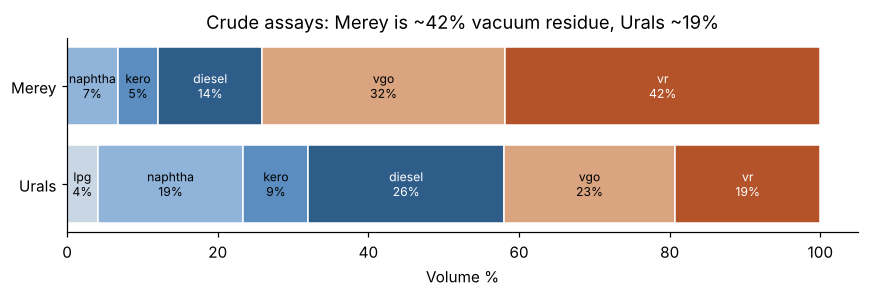

In [3]:
rows = []
for c, a in lp.ASSAYS.items():
    for k, (vol, sg, s) in a["cuts"].items():
        rows.append((c.title(), k, vol * 100, sg, s))
assay = pd.DataFrame(rows, columns=["crude", "cut", "vol %", "SG", "sulfur wt%"])
display(assay.pivot(index="cut", columns="crude", values=["vol %", "sulfur wt%"]).loc[["lpg", "naphtha", "kero", "diesel", "vgo", "vr"]])
print({c: f"API {a['api']}, S {a['sulfur']}% ({a['source']})" for c, a in lp.ASSAYS.items()})

fig, ax = plt.subplots(figsize=(8, 2.8))
order = ["lpg", "naphtha", "kero", "diesel", "vgo", "vr"]
cols = ["#C9D6E3", "#8FB3D9", "#5B8DC0", "#2F5D8A", "#D9A47F", "#B4532A"]
for i, c in enumerate(["urals", "merey"]):
    left = 0
    for k, col in zip(order, cols):
        w = lp.ASSAYS[c]["cuts"][k][0] * 100
        ax.barh(c.title(), w, left=left, color=col, edgecolor="white")
        if w > 4: ax.text(left + w / 2, i, f"{k}\n{w:.0f}%", ha="center", va="center", fontsize=8, color="white" if k in ("diesel", "vr") else "black")
        left += w
ax.set_xlabel("Volume %"); ax.set_title("Crude assays: Merey is ~42% vacuum residue, Urals ~19%"); ax.grid(False)
plt.tight_layout(); plt.show()

### 1c. Unit capacities

The units are scaled from Jamnagar's SEZ refinery (A Barrel Full, 2012) to a 580 kb/d train.

In [4]:
cap = pd.DataFrame({"SEZ capacity (kb/d)": lp.SEZ, "per bbl of crude": lp.CAP_RATIO})
display(cap)

,SEZ capacity (kb/d),per bbl of crude
cdu,580,1.00
vdu,305,0.53
fcc,200,0.34
hcu,110,0.19
coker,160,0.28
reformer,127,0.22
product_ht,360,0.62


## 2. The model

For a given slate, `refinery_lp.solve()` maximises

`Product revenue + petcoke value + sulfur credit − crude cost − unit opex − hydrogen cost`

subject to:
* **Vacuum unit:** atmospheric residue above capacity has to be sold as fuel oil.
* **Coker:** vacuum residue above capacity has to be sold as fuel oil.
* **FCC and hydrocracker:** compete for gasoil feed (VGO plus coker heavy gasoil). Hydrogen is priced off LNG.
* **Reformer/isomerisation:** upgrades naphtha to gasoline; any surplus is sold as naphtha.
* **Hydrotreaters:** distillate above capacity is sold as high-sulfur gasoil at a $15 discount.

The **Merey advantage** is the margin of a train running 580 kb/d of Urals compared with the same train when `venez_kbd` of it is swapped to Merey, per barrel swapped. Unit yields and costs are textbook values in `refinery_lp.py` (estimates).

In [5]:
TRAIN = 580.0

def prices(p):
    return lp.Prices(
        brent=p["brent"],
        cracks=dict(lpg=p["crack_lpg"], gasoline=p["crack_gasoline"], jet=p["crack_jet"], diesel=p["crack_diesel"],
                    fuel_oil=p["crack_fuel_oil"], naphtha=p["crack_naphtha"]),
        crude_cost={"urals": p["brent"] + p["urals_dap_diff"],
                    "merey": p["brent"] + p["merey_diff"] + p["merey_freight"] + p["merey_insurance"]},
        lng=p["lng_usd_mmbtu"],
        sulfur_usd_t=p["sulfur_fob"] * p["sulfur_realisation"],
        petcoke_usd_t=30.0 * 0.65 * p["lng_usd_mmbtu"] - 60.0,   # gasified to replace LNG (30 MMBtu/t, 65% eff., $60/t cost)
    )

def run(p, merey_kbd=None):
    M = p["venez_kbd"] if merey_kbd is None else merey_kbd
    P = prices(p)
    base = lp.solve({"urals": TRAIN}, P, cap_scale=p["capacity_scale"])
    swap = lp.solve({"urals": TRAIN - M, "merey": M}, P, cap_scale=p["capacity_scale"])
    assert base.status == swap.status == "Optimal"
    return base, swap

def advantage(p, merey_kbd=None):
    M = p["venez_kbd"] if merey_kbd is None else merey_kbd
    base, swap = run(p, M)
    return (swap.margin_usd_k_day - base.margin_usd_k_day) / M

def with_(**kw):
    q = dict(BASE); q.update(kw); return q
annual = lambda adv, p=BASE: adv * p["venez_kbd"] * 1000 * 365 / 1e6

## 3. Base case

In [6]:
base, swap = run(BASE)
M = BASE["venez_kbd"]
u = advantage(BASE)

units = pd.DataFrame({"capacity": base.detail["cap"] | {"fuel_oil_from_ar": np.nan, "fuel_oil_from_vr": np.nan},
                      "All Urals": base.units, f"+{M:.0f} kb/d Merey": swap.units}).loc[
    ["vdu", "coker", "fcc", "hcu", "reformer", "product_ht", "fuel_oil_from_ar", "fuel_oil_from_vr"]]
print("Unit loadings (kb/d). Fuel-oil rows = residue that could not be upgraded:")
display(units)

prods = pd.DataFrame({"All Urals": base.products, f"+{M:.0f} kb/d Merey": swap.products})
prods.loc["petcoke (t/d)"] = [base.coke_t_day, swap.coke_t_day]
prods.loc["sulfur (t/d)"] = [base.sulfur_t_day, swap.sulfur_t_day]
print("Products (kb/d unless noted):"); display(prods)

print(f"Margin: all-Urals ${base.margin_usd_k_day/1000:,.2f} M/day · with Merey ${swap.margin_usd_k_day/1000:,.2f} M/day")
print(f"Merey advantage: {u:+.2f} $/bbl  →  {annual(u):+,.0f} $ mn/yr (≈ ₹{annual(u)*1e6*BASE['usd_inr']/1e7:+,.0f} crore) at {M:.0f} kb/d")

Unit loadings (kb/d). Fuel-oil rows = residue that could not be upgraded:


,capacity,All Urals,+280 kb/d Merey
vdu,305.00,243.62,305.00
coker,160.00,111.82,158.90
fcc,200.00,55.35,81.75
hcu,110.00,110.00,110.00
reformer,127.00,127.00,121.31
product_ht,360.00,238.47,208.82
fuel_oil_from_ar,NaN,0.00,28.55
fuel_oil_from_vr,NaN,0.00,0.00


Products (kb/d unless noted):


,All Urals,+280 kb/d Merey
lpg,52.33,45.58
gasoline,138.62,149.74
naphtha,25.18,0.00
jet,77.51,68.51
diesel,248.96,228.30
hsgo,0.00,0.00
fuel_oil,3.87,34.27
petcoke (t/d),"4,835.94","8,604.22"
sulfur (t/d),810.44,"1,185.44"


Margin: all-Urals $19.65 M/day · with Merey $19.86 M/day
Merey advantage: +0.73 $/bbl  →  +75 $ mn/yr (≈ ₹+706 crore) at 280 kb/d


### What one barrel of Merey actually yields, compared with the v3 estimates

The LP's incremental yield per barrel of Merey is: the change in products, divided by the Merey volume, plus the Urals barrel it displaced.

,v3 estimate %,LP (assay-based) %
lpg,3.00,6.60
naphtha,0.00,-4.70
gasoline,22.00,27.90
jet,11.00,10.20
diesel,44.00,35.50
hsgo,0.00,0.00
fuel_oil,4.00,11.50
petcoke,11.00,13.60
loss / gain,5.00,-0.70


Note: LP yields are whole-refinery effects. Naphtha is negative because adding Merey frees reformer space, so straight-run naphtha that was being sold is upgraded into gasoline instead; the gasoline line rises by more than naphtha falls.


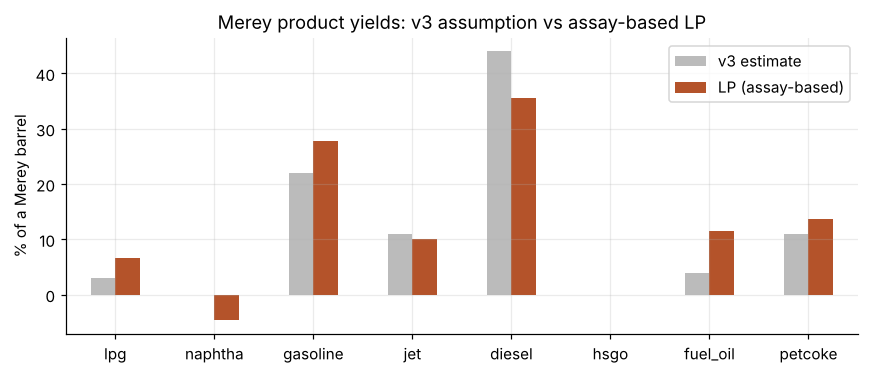

In [7]:
COKE_T_PER_BBL_EQ = 0.16
inc = {k: (swap.products[k] - base.products[k]) / M + base.products[k] / TRAIN for k in base.products}
inc_coke = ((swap.coke_t_day - base.coke_t_day) / M + base.coke_t_day / TRAIN) / 1000 / COKE_T_PER_BBL_EQ
v3 = dict(lpg=.03, naphtha=0.0, gasoline=.22, jet=.11, diesel=.44, hsgo=0.0, fuel_oil=.04, petcoke=.11)
lpy = {**inc, "petcoke": inc_coke}
cmp_ = pd.DataFrame({"v3 estimate": v3, "LP (assay-based)": lpy}).fillna(0)
cmp_.loc["loss / gain"] = 1 - cmp_.sum()
display((cmp_ * 100).round(1).rename(columns=lambda c: c + " %"))
print("Note: LP yields are whole-refinery effects. Naphtha is negative because adding Merey frees reformer space, so straight-run "
      "naphtha that was being sold is upgraded into gasoline instead; the gasoline line rises by more than naphtha falls.")

ax = (cmp_.drop("loss / gain") * 100).plot.bar(figsize=(8, 3.5), color=["#BBBBBB", MEREY_C], rot=0)
ax.set_ylabel("% of a Merey barrel"); ax.set_title("Merey product yields: v3 assumption vs assay-based LP")
plt.tight_layout(); plt.show()

### Margin bridge per barrel of Merey

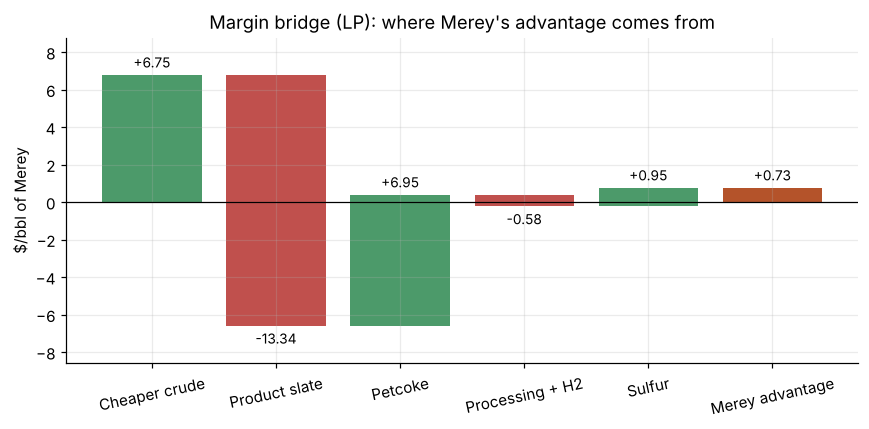

In [8]:
coke_val = lambda r: r.coke_t_day / 1000 * prices(BASE).petcoke_usd_t
d = lambda f: (f(swap) - f(base)) / M
steps = [("Cheaper crude", -d(lambda r: r.detail["crude_cost"])),
         ("Product slate", d(lambda r: r.detail["revenue"] - coke_val(r))),
         ("Petcoke", d(coke_val)),
         ("Processing + H2", -d(lambda r: r.detail["opex"] + r.detail["h2"])),
         ("Sulfur", d(lambda r: r.detail["sulfur_credit"]))]
fig, ax = plt.subplots(figsize=(8, 4)); run_ = 0; lo_, hi_ = 0, 0
for i, (lab, v) in enumerate(steps):
    ax.bar(lab, v, bottom=run_, color="#4C9A6A" if v >= 0 else "#C0504D")
    run_ += v; lo_, hi_ = min(lo_, run_), max(hi_, run_)
    ax.text(i, (run_ + .25) if v >= 0 else (run_ - .25), f"{v:+.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax.bar("Merey advantage", run_, color=MEREY_C); ax.text(len(steps), max(run_, 0) + .25, f"{run_:+.2f}", ha="center", va="bottom", fontsize=9)
pad = 0.15 * (hi_ - lo_); ax.set_ylim(lo_ - pad, hi_ + pad)
ax.axhline(0, color="black", lw=.8); ax.set_ylabel("$/bbl of Merey")
ax.set_title("Margin bridge (LP): where Merey's advantage comes from"); plt.xticks(rotation=12); plt.tight_layout(); plt.show()
assert abs(run_ - u) < 1e-6

## 4. How much Merey can Jamnagar absorb?

This section, only possible with the LP, swaps progressively more Urals for Merey and tracks the **average** and **marginal** value per barrel.

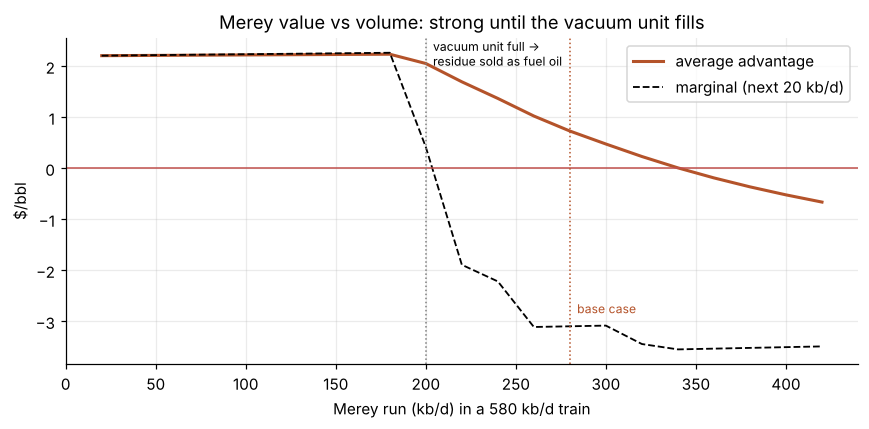

Vacuum unit fills at ~200 kb/d of Merey. Total gain peaks around 200 kb/d. Marginal barrels lose money beyond ~220 kb/d.


In [9]:
vols = np.arange(20, 421, 20)
avg, marg, vdu_fo = [], [], []
b0, _ = run(BASE, 20)
prev_total = 0.0
for v in vols:
    b, s = run(BASE, v)
    total = s.margin_usd_k_day - b.margin_usd_k_day
    avg.append(total / v); marg.append((total - prev_total) / 20); prev_total = total
    vdu_fo.append(s.units["fuel_oil_from_ar"] + s.units["fuel_oil_from_vr"])
curve = pd.DataFrame({"avg $/bbl": avg, "marginal $/bbl": marg, "residue to fuel oil (kb/d)": vdu_fo}, index=vols)
curve.index.name = "Merey kb/d"

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(vols, avg, color=MEREY_C, lw=2, label="average advantage")
ax.plot(vols, marg, color="black", ls="--", lw=1.2, label="marginal (next 20 kb/d)")
ax.axhline(0, color="#C0504D", lw=1)
first_fo = vols[np.argmax(np.array(vdu_fo) > 0.5)]
ax.axvline(first_fo, color="grey", ls=":", lw=1); ax.text(first_fo + 4, max(avg) * 0.9, "vacuum unit full →\nresidue sold as fuel oil", fontsize=8)
ax.axvline(BASE["venez_kbd"], color=MEREY_C, ls=":", lw=1); ax.text(BASE["venez_kbd"] + 4, min(marg) * 0.8, "base case", fontsize=8, color=MEREY_C)
ax.set_xlabel("Merey run (kb/d) in a 580 kb/d train"); ax.set_ylabel("$/bbl"); ax.legend()
ax.set_title("Merey value vs volume: strong until the vacuum unit fills"); plt.tight_layout(); plt.show()

opt = vols[np.argmax(np.array(avg) * vols)]
zero_m = vols[np.argmax(np.array(marg) < 0)] if (np.array(marg) < 0).any() else None
print(f"Vacuum unit fills at ~{first_fo} kb/d of Merey. Total gain peaks around {opt} kb/d.",
      f"Marginal barrels lose money beyond ~{zero_m} kb/d." if zero_m else "")

## 5. Implied break-even discount

In [10]:
def breakeven_diff(p=BASE):
    return brentq(lambda d: advantage({**p, "merey_diff": d}), -60, 30)

be = breakeven_diff()
print(f"Break-even Merey differential at {BASE['venez_kbd']:.0f} kb/d: Brent {be:+.2f} $/bbl")
print("Reference points: official Sep Merey −20.4 · PDVSA–JV deals −12 to −13 · trader bids −18 to −20")
rows = [(v, breakeven_diff(with_(venez_kbd=v))) for v in [100, 150, 200, 250, 280, 350]]
display(pd.DataFrame(rows, columns=["Merey kb/d", "break-even diff ($/bbl)"]).set_index("Merey kb/d"))

Break-even Merey differential at 280 kb/d: Brent -15.77 $/bbl
Reference points: official Sep Merey −20.4 · PDVSA–JV deals −12 to −13 · trader bids −18 to −20


,break-even diff ($/bbl)
Merey kb/d,
100,-14.28
150,-14.27
200,-14.45
250,-15.31
280,-15.77
350,-16.59


## 6. Scenarios, including low and high estimates

In [11]:
est_keys = INPUTS.index[INPUTS.type == E]
def case(col, keys):
    q = dict(BASE); q.update(INPUTS.loc[keys, col].to_dict()); return q
cases = {
  "Base": BASE,
  "Estimate inputs LOW": case("low", est_keys),
  "Estimate inputs HIGH": case("high", est_keys),
  "Sept pricing (Urals +$8)": with_(urals_dap_diff=8.0),
  "Official Merey price (−$20.4)": with_(merey_diff=-20.4),
  "JV-deal price (−$12.5)": with_(merey_diff=-12.5),
  "Diesel crack falls to $40": with_(crack_diesel=40.0, crack_jet=38.0),
  "Gasoline back to record $50": with_(crack_gasoline=50.0),
  "LNG falls to $15": with_(lng_usd_mmbtu=15.0),
  "Sulfur collapses to $600": with_(sulfur_fob=600.0),
  "Freight spike to $12": with_(merey_freight=12.0),
  "+30% coking/vacuum headroom": with_(capacity_scale=1.3),
  "Run only 180 kb/d": with_(venez_kbd=180.0),
}
C = pd.DataFrame([dict(case=k, adv_per_bbl=advantage(p), kbd=p["venez_kbd"], annual_usd_mn=annual(advantage(p), p))
                  for k, p in cases.items()]).set_index("case")
display(C)

,adv_per_bbl,kbd,annual_usd_mn
case,,,
Base,0.73,280.00,74.66
Estimate inputs LOW,2.04,200.00,148.74
Estimate inputs HIGH,0.12,350.00,15.61
Sept pricing (Urals +$8),8.73,280.00,892.26
Official Merey price (−$20.4),4.63,280.00,473.24
JV-deal price (−$12.5),-3.27,280.00,-334.14
Diesel crack falls to $40,3.91,280.00,399.36
Gasoline back to record $50,1.80,280.00,184.25
LNG falls to $15,-1.24,280.00,-126.94


## 7. Tornado: each input across its low–high range

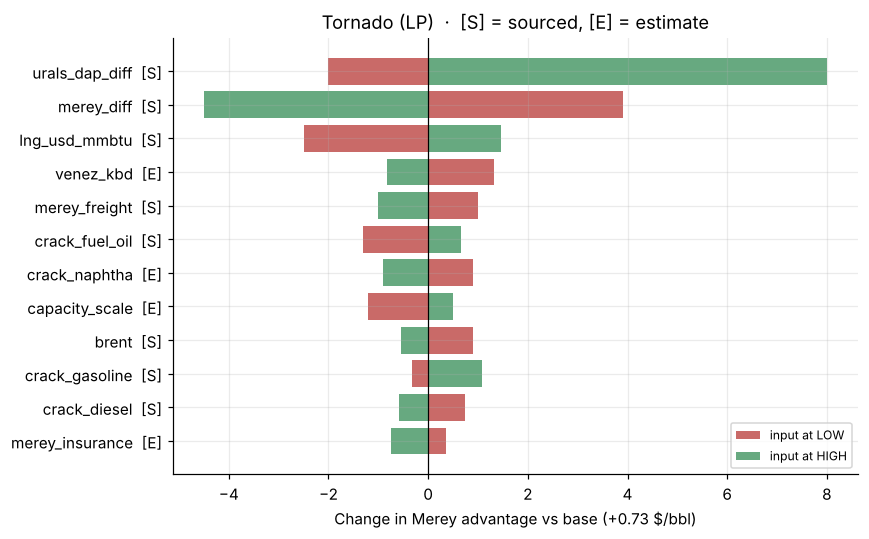

In [12]:
rows = []
for k in INPUTS.index:
    if k == "usd_inr":
        continue
    lo, hi = advantage(with_(**{k: INPUTS.loc[k, "low"]})), advantage(with_(**{k: INPUTS.loc[k, "high"]}))
    rows.append((k, INPUTS.loc[k, "type"], lo - u, hi - u))
tor = pd.DataFrame(rows, columns=["input", "type", "at_low", "at_high"])
tor["range"] = (tor.at_high - tor.at_low).abs()
tor = tor.sort_values("range").tail(12)
fig, ax = plt.subplots(figsize=(8, 5))
labels = [f"{r.input}  [{'S' if r.type == S else 'E'}]" for r in tor.itertuples()]
ax.barh(labels, tor.at_low, color="#C0504D", alpha=.85, label="input at LOW")
ax.barh(labels, tor.at_high, color="#4C9A6A", alpha=.85, label="input at HIGH")
ax.axvline(0, color="black", lw=.8); ax.set_xlabel(f"Change in Merey advantage vs base ({u:+.2f} $/bbl)")
ax.set_title("Tornado (LP)  ·  [S] = sourced, [E] = estimate"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 8. Heatmap: Merey discount × freight

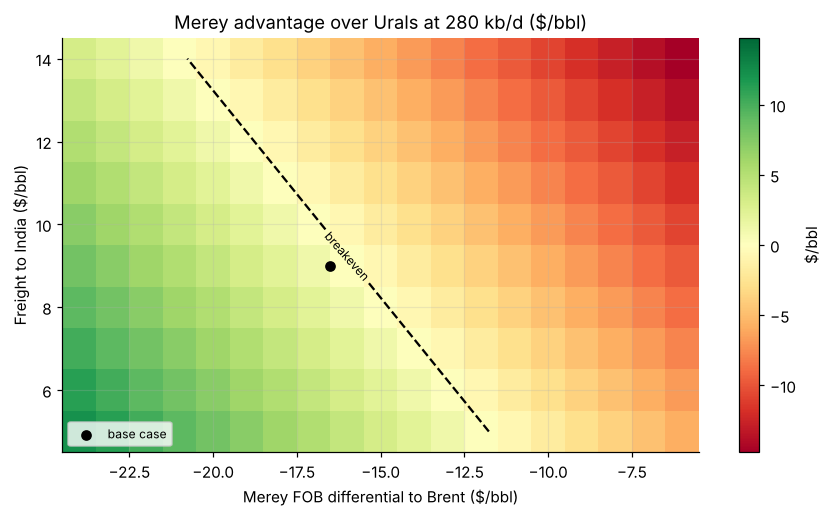

In [13]:
discs = np.arange(-24, -5.9, 1.0); frts = np.arange(5, 14.1, 1.0)
grid = np.array([[advantage(with_(merey_diff=d, merey_freight=f)) for d in discs] for f in frts])
fig, ax = plt.subplots(figsize=(8, 4.8)); lim = np.abs(grid).max()
im = ax.pcolormesh(discs, frts, grid, cmap="RdYlGn", vmin=-lim, vmax=lim, shading="nearest")
cs = ax.contour(discs, frts, grid, levels=[0], colors="black", linestyles="--"); ax.clabel(cs, fmt="breakeven", fontsize=8)
ax.scatter([BASE["merey_diff"]], [BASE["merey_freight"]], color="black", zorder=5, label="base case")
ax.set_xlabel("Merey FOB differential to Brent ($/bbl)"); ax.set_ylabel("Freight to India ($/bbl)")
ax.set_title(f"Merey advantage over Urals at {BASE['venez_kbd']:.0f} kb/d ($/bbl)"); ax.legend(loc="lower left", fontsize=8)
fig.colorbar(im, ax=ax, label="$/bbl"); plt.tight_layout(); plt.show()

## 9. Monte Carlo

3,000 draws. Every input with a range is drawn from a triangular distribution (low, base, high), and the LP is re-solved for each draw.

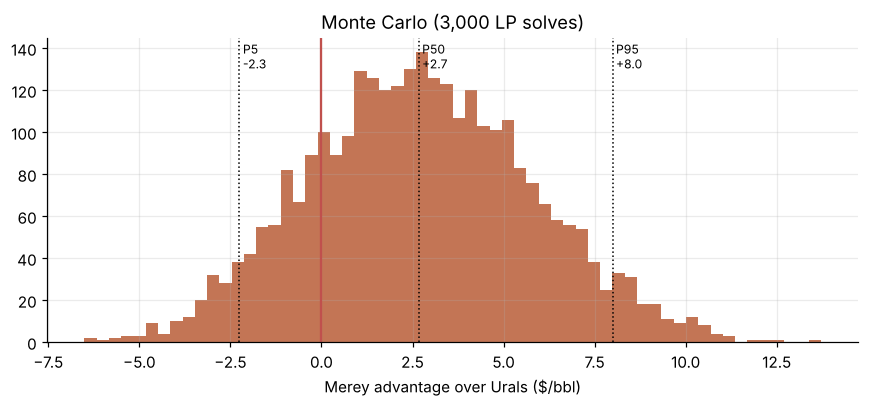

P(Merey beats Urals) = 80.4%   ·   P5 / P50 / P95 = -2.25 / +2.67 / +7.99 $/bbl


,correlation with outcome
urals_dap_diff,0.69
merey_diff,-0.54
lng_usd_mmbtu,0.29
merey_freight,-0.14
venez_kbd,-0.13
capacity_scale,0.11


In [14]:
rng = np.random.default_rng(7); N = 3000
draw_keys = [k for k in INPUTS.index if INPUTS.loc[k, "low"] != INPUTS.loc[k, "high"] and k != "usd_inr"]
D = {k: rng.triangular(INPUTS.loc[k, "low"], INPUTS.loc[k, "base"], INPUTS.loc[k, "high"], N) for k in draw_keys}
res = np.array([advantage({**BASE, **{k: D[k][i] for k in draw_keys}}) for i in range(N)])
p5, p50, p95 = np.percentile(res, [5, 50, 95])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(res, bins=60, color=MEREY_C, alpha=.8); ax.axvline(0, color="#C0504D", lw=1.5)
for v, lab in [(p5, "P5"), (p50, "P50"), (p95, "P95")]:
    ax.axvline(v, color="black", ls=":", lw=1); ax.text(v, ax.get_ylim()[1] * .9, f" {lab}\n {v:+.1f}", fontsize=8)
ax.set_xlabel("Merey advantage over Urals ($/bbl)"); ax.set_title(f"Monte Carlo ({N:,} LP solves)")
plt.tight_layout(); plt.show()
corr = pd.Series({k: np.corrcoef(D[k], res)[0, 1] for k in draw_keys}).sort_values(key=abs, ascending=False)
print(f"P(Merey beats Urals) = {(res > 0).mean():.1%}   ·   P5 / P50 / P95 = {p5:+.2f} / {p50:+.2f} / {p95:+.2f} $/bbl")
display(corr.head(6).to_frame("correlation with outcome"))

## 10. Summary

In [15]:
s = dict(steps)
print(f"""At 22 Oct 2026 prices, swapping {BASE['venez_kbd']:.0f} kb/d of Urals for Merey (Brent {BASE['merey_diff']:+.1f}) earns {u:+.2f} $/bbl
({annual(u):+,.0f} $ mn/yr) in an assay-based LP of a Jamnagar-style 580 kb/d train. Break-even differential: Brent {be:+.1f}.

Where it comes from (per bbl of Merey): cheaper crude {s['Cheaper crude']:+.2f}, product slate {s['Product slate']:+.2f},
petcoke {s['Petcoke']:+.2f}, processing + hydrogen {s['Processing + H2']:+.2f}, sulfur {s['Sulfur']:+.2f}.

Capacity is the binding constraint: the vacuum unit fills at ~{first_fo} kb/d of Merey, after which surplus residue is sold as
fuel oil and each extra barrel is worth much less. Running ~180 kb/d earns {C.loc['Run only 180 kb/d','adv_per_bbl']:+.2f} $/bbl;
30% more coking/vacuum headroom (Jamnagar's DTA refinery) lifts the base case to {C.loc['+30% coking/vacuum headroom','adv_per_bbl']:+.2f} $/bbl.

Monte Carlo: Merey wins in {(res > 0).mean():.0%} of {N:,} runs. At September's Urals premium, Merey was worth
{C.loc['Sept pricing (Urals +$8)','adv_per_bbl']:+.2f} $/bbl, consistent with October's import surge.""")

At 22 Oct 2026 prices, swapping 280 kb/d of Urals for Merey (Brent -16.5) earns +0.73 $/bbl
(+75 $ mn/yr) in an assay-based LP of a Jamnagar-style 580 kb/d train. Break-even differential: Brent -15.8.

Where it comes from (per bbl of Merey): cheaper crude +6.75, product slate -13.34,
petcoke +6.95, processing + hydrogen -0.58, sulfur +0.95.

Capacity is the binding constraint: the vacuum unit fills at ~200 kb/d of Merey, after which surplus residue is sold as
fuel oil and each extra barrel is worth much less. Running ~180 kb/d earns +2.24 $/bbl;
30% more coking/vacuum headroom (Jamnagar's DTA refinery) lifts the base case to +1.24 $/bbl.

Monte Carlo: Merey wins in 80% of 3,000 runs. At September's Urals premium, Merey was worth
+8.73 $/bbl, consistent with October's import surge.


## Limitations
| Area | Simplification | Better data |
|---|---|---|
| Merey assay | OGJ 1997 Merey (14.7°API); today's Merey 16 is slightly lighter | PDVSA/Platts current assay |
| Urals assay | Bulk yields public; VGO/residue split and cut sulfur estimated | Full TotalEnergies/BP assay |
| Units | SEZ capacities (2012), DTA refinery excluded; textbook unit yields | Reliance disclosures, licensor yield curves |
| Pricing | One-day snapshot; jet/LPG/naphtha cracks estimated | Platts/Argus time series |
| Calibration | Not yet checked against Reliance's reported GRM | Reliance Q2 FY27 results |

## Sources
- **Assays:** Oil & Gas Journal, *Guide to World Crudes: assays of two Venezuelan crudes* (Merey, 9 Jun 1997); A Barrel Full and The Petro Solutions (Urals specifications)
- **Units:** A Barrel Full, *Jamnagar Refinery II* (SEZ unit capacities); NS Energy (complex overview)
- **Prices:** Oilprice.com (Brent, Urals, JKM, OPEC Merey Sep; 22 Oct 2026); EIA Brent monthly spot (21 Oct 2026); Quantum Commodity Intelligence East of Suez reports (16–21 Oct 2026); TradingView (Singapore 380cst crack); Argus Media (QatarEnergy Oct sulphur, 30 Sep 2026)
- **Trade flows and contracts:** Reuters via Rio Times (Merey discounts, 22 Sep 2026); Baird Maritime/Reuters (Urals premiums, 15 Oct 2026); Business Standard (freight, 14 Aug 2026); Kpler via Business Today (7 Oct 2026); Goodreturns (USD/INR)